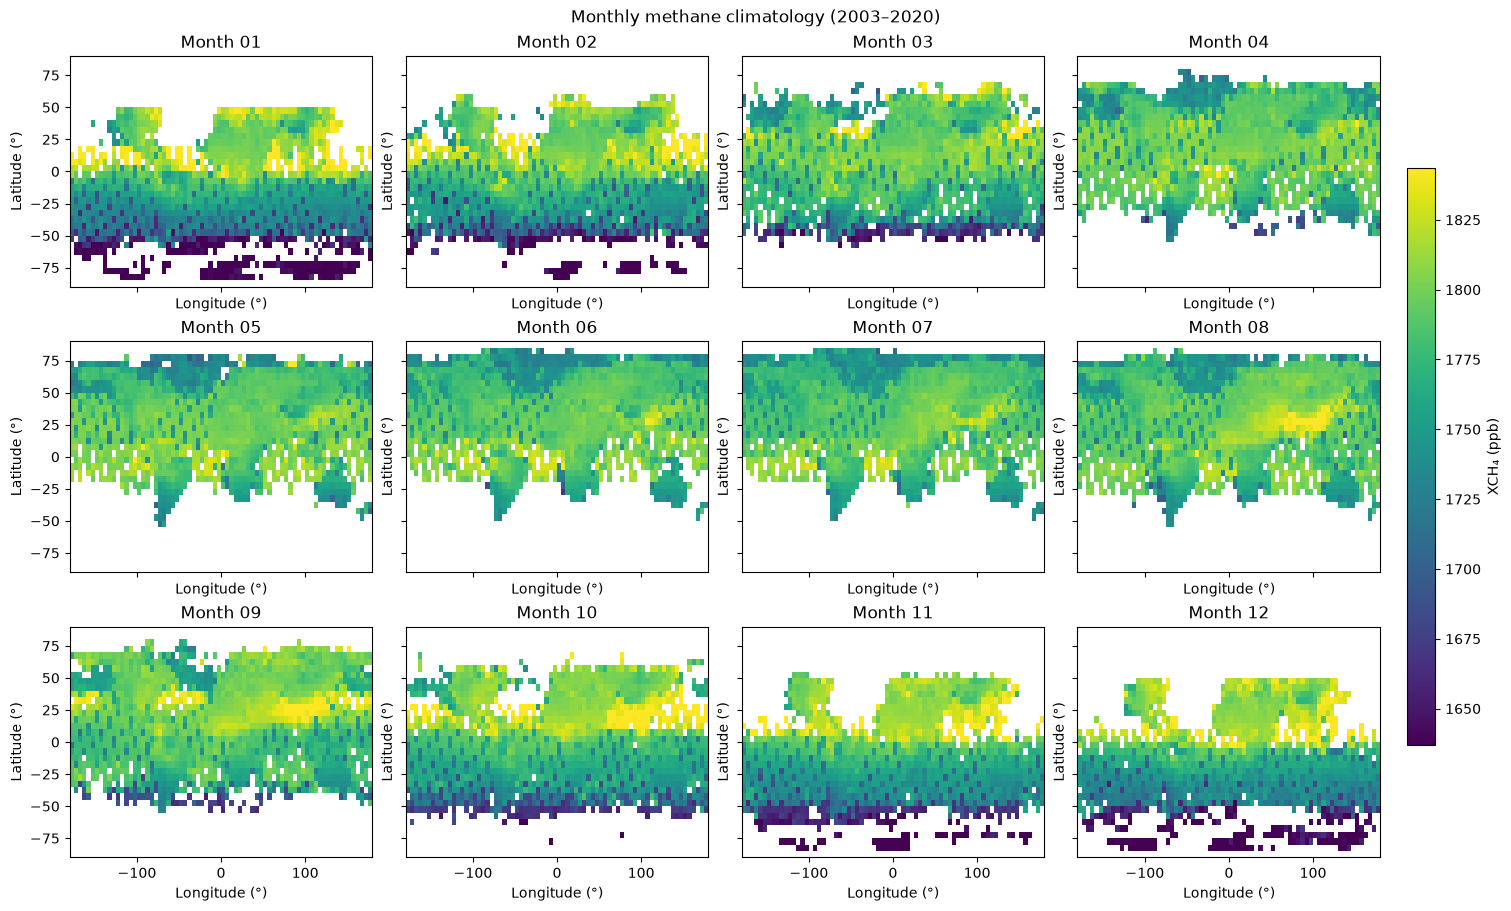

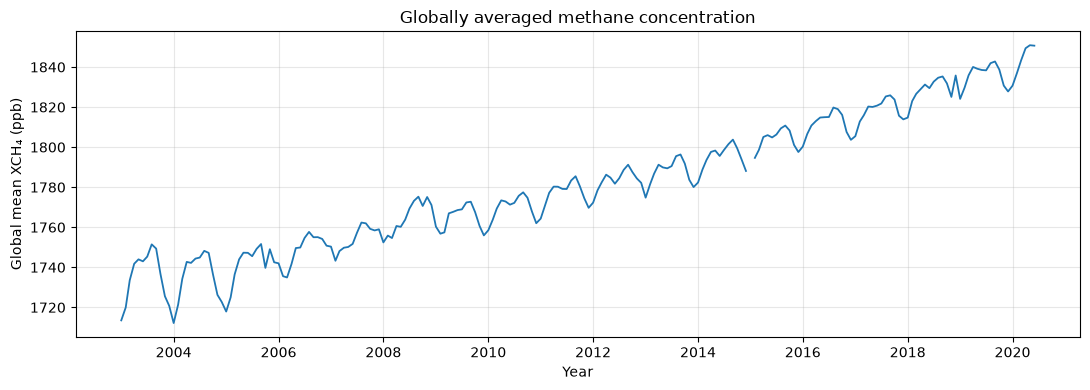

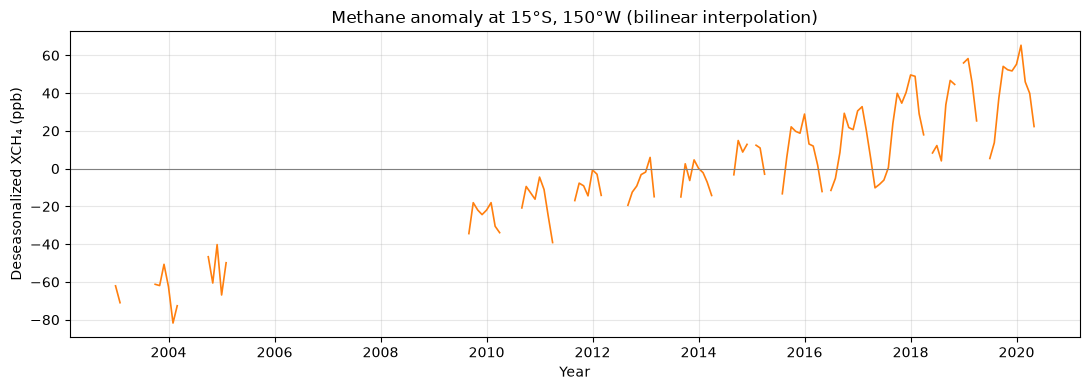

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from netCDF4 import Dataset, num2date

file = "200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"

with Dataset(file) as ds:
    lat = np.asarray(ds["lat"][:])
    lon = np.asarray(ds["lon"][:])

    ch4_var = ds["xch4"]
    ch4_var.set_auto_mask(False)
    ch4 = np.asarray(ch4_var[:], dtype=float)

    time_var = ds["time"]
    dates = num2date(
        time_var[:],
        units=time_var.units,
        calendar=getattr(time_var, "calendar", "standard")
    )
    time = np.array([
        np.datetime64(f"{date.year:04d}-{date.month:02d}-01")
        for date in dates
    ])

# 处理缺测值，并将甲烷摩尔分数转换为 ppb
ch4[~np.isfinite(ch4) | (ch4 >= 1e19)] = np.nan
ch4 *= 1e9
months = np.array([int(str(date)[5:7]) for date in time])


def valid_mean(values, axis):
    """计算有效数据的平均值；全为缺测值时返回 NaN。"""
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    mean = np.full(np.shape(total), np.nan, dtype=float)
    np.divide(total, count, out=mean, where=count > 0)
    return mean


# 1.1 计算各月甲烷气候态
climatology = np.stack([
    valid_mean(ch4[months == month], axis=0)
    for month in range(1, 13)
])

fig, axes = plt.subplots(
    3, 4, figsize=(15, 9),
    sharex=True, sharey=True,
    layout="constrained"
)

vmin, vmax = np.nanpercentile(climatology, [2, 98])

for month, ax in enumerate(axes.flat, start=1):
    image = ax.pcolormesh(
        lon, lat, climatology[month - 1],
        shading="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(f"Month {month:02d}")
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")

fig.colorbar(image, ax=axes, label="XCH₄ (ppb)", shrink=0.72, pad=0.02)
fig.suptitle("Monthly methane climatology (2003–2020)")
plt.show()


# 1.2 计算全球面积加权平均甲烷浓度
weights = np.cos(np.deg2rad(lat))[None, :, None]
valid = np.isfinite(ch4)

weighted_sum = np.nansum(ch4 * weights, axis=(1, 2))
weight_sum = np.sum(np.where(valid, weights, 0), axis=(1, 2))

global_mean = np.full(len(time), np.nan)
np.divide(
    weighted_sum,
    weight_sum,
    out=global_mean,
    where=weight_sum > 0
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(time, global_mean, color="tab:blue", linewidth=1.3)
ax.set(
    xlabel="Year",
    ylabel="Global mean XCH₄ (ppb)",
    title="Globally averaged methane concentration"
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 1.3 插值到 15°S、150°W，计算去季节变化甲烷序列
target_lat = -15
target_lon = -150

lat_hi = np.searchsorted(lat, target_lat)
lon_hi = np.searchsorted(lon, target_lon)
lat_lo = lat_hi - 1
lon_lo = lon_hi - 1

fy = (target_lat - lat[lat_lo]) / (lat[lat_hi] - lat[lat_lo])
fx = (target_lon - lon[lon_lo]) / (lon[lon_hi] - lon[lon_lo])

corners = np.stack([
    ch4[:, lat_lo, lon_lo],
    ch4[:, lat_lo, lon_hi],
    ch4[:, lat_hi, lon_lo],
    ch4[:, lat_hi, lon_hi]
], axis=1)

corner_weights = np.array([
    (1 - fy) * (1 - fx),
    (1 - fy) * fx,
    fy * (1 - fx),
    fy * fx
])

# 若某个相邻格点缺测，仅使用其余有效格点
valid_corners = np.isfinite(corners)
point_sum = np.nansum(corners * corner_weights, axis=1)
point_weight = np.sum(
    np.where(valid_corners, corner_weights, 0),
    axis=1
)

point_series = np.full(len(time), np.nan)
np.divide(
    point_sum,
    point_weight,
    out=point_series,
    where=point_weight > 0
)

point_climatology = np.array([
    valid_mean(point_series[months == month], axis=0)
    for month in range(1, 13)
])
point_anomaly = point_series - point_climatology[months - 1]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(time, point_anomaly, color="tab:orange", linewidth=1.2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    xlabel="Year",
    ylabel="Deseasonalized XCH₄ (ppb)",
    title="Methane anomaly at 15°S, 150°W (bilinear interpolation)"
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

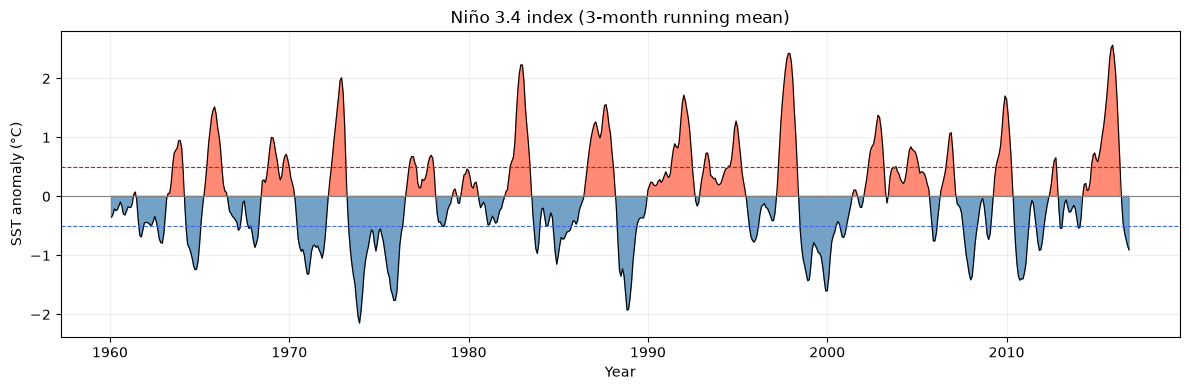

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from netCDF4 import Dataset, num2date

file = "NOAA_NCDC_ERSST_v3b_SST.nc"

with Dataset(file) as ds:
    lat = np.asarray(ds["lat"][:])
    lon = np.asarray(ds["lon"][:])
    sst = np.ma.filled(ds["sst"][:], np.nan).astype(float)

    time_var = ds["time"]
    dates = num2date(time_var[:], time_var.units)
    time = np.array([
        np.datetime64(f"{d.year:04d}-{d.month:02d}-01")
        for d in dates
    ])

months = np.array([int(str(date)[5:7]) for date in time])

# Niño 3.4：5°S–5°N，170°W–120°W
# 数据经度为 0°–360°，因此选择 190°E–240°E
lat_mask = (lat >= -5) & (lat <= 5)
lon_mask = (lon >= 190) & (lon <= 240)
region = sst[:, lat_mask, :][:, :, lon_mask]

weights = np.cos(np.deg2rad(lat[lat_mask]))[None, :, None]
valid = np.isfinite(region)

regional_sst = (
    np.nansum(region * weights, axis=(1, 2))
    / np.sum(np.where(valid, weights, 0), axis=(1, 2))
)

# 2.1 计算逐月气候态，并从 SST 序列中扣除
climatology = np.array([
    np.nanmean(regional_sst[months == month])
    for month in range(1, 13)
])
anomaly = regional_sst - climatology[months - 1]

# 对距平计算居中的三个月滑动平均
nino34 = np.full(len(anomaly), np.nan)
nino34[1:-1] = (
    anomaly[:-2] + anomaly[1:-1] + anomaly[2:]
) / 3


# 2.2 绘制 Niño 3.4 指数
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time, nino34, color="black", linewidth=0.8)

ax.fill_between(
    time, 0, nino34,
    where=nino34 >= 0, color="tomato", alpha=0.75
)
ax.fill_between(
    time, 0, nino34,
    where=nino34 < 0, color="steelblue", alpha=0.75
)

ax.axhline(0.5, color="firebrick", linestyle="--", linewidth=0.8)
ax.axhline(-0.5, color="royalblue", linestyle="--", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    xlabel="Year",
    ylabel="SST anomaly (°C)",
    title="Niño 3.4 index (3-month running mean)"
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

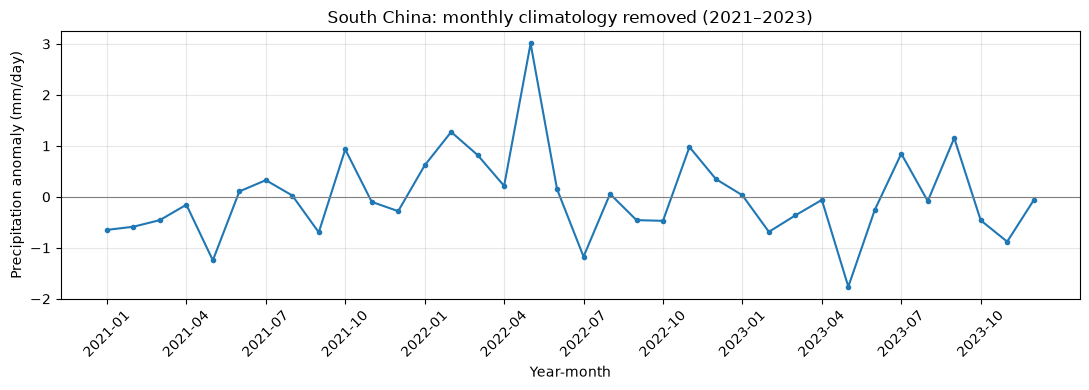

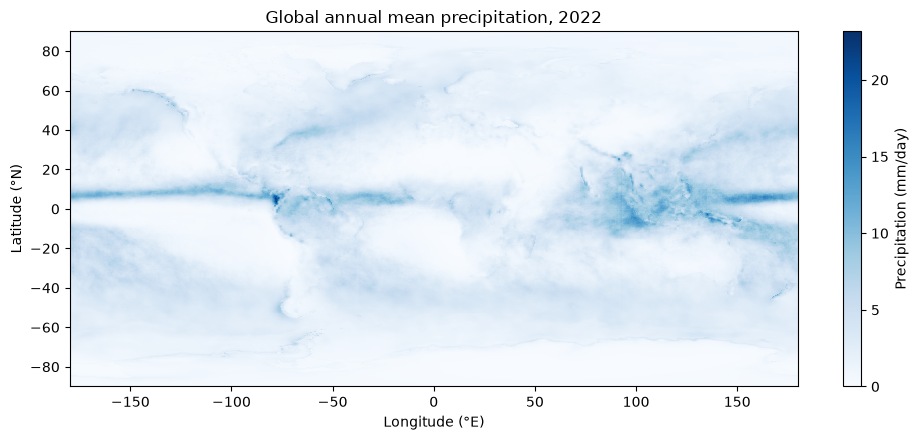

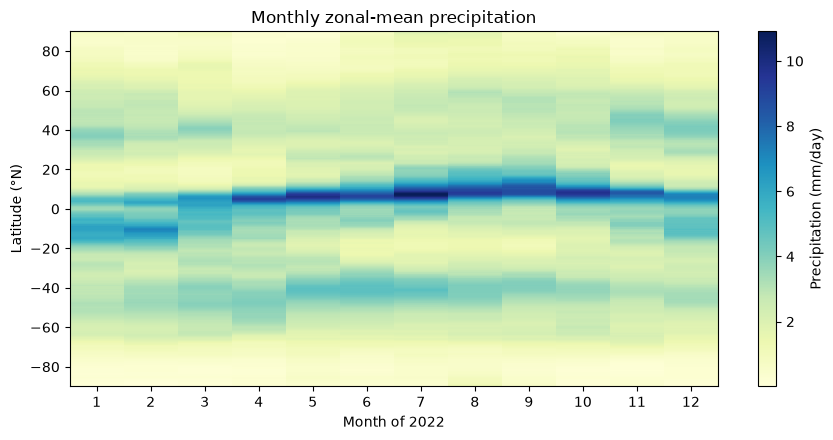

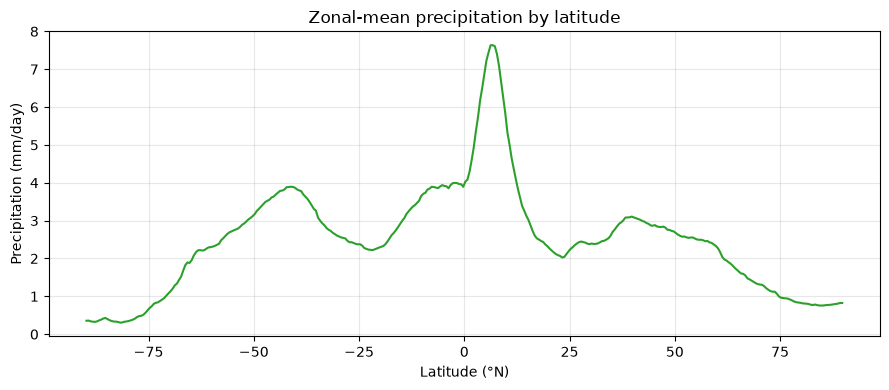

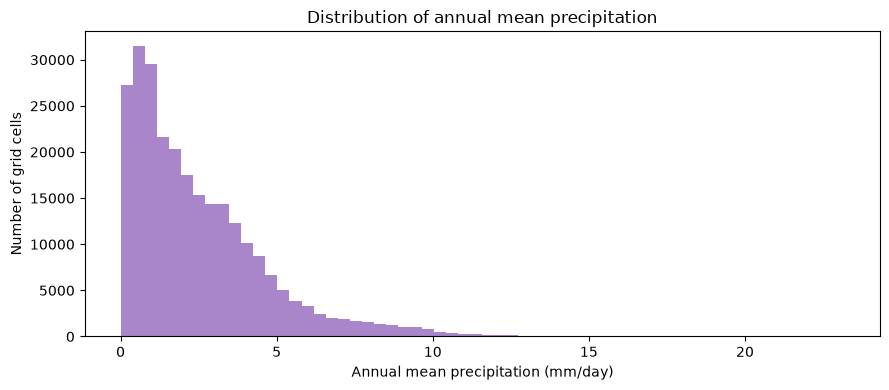

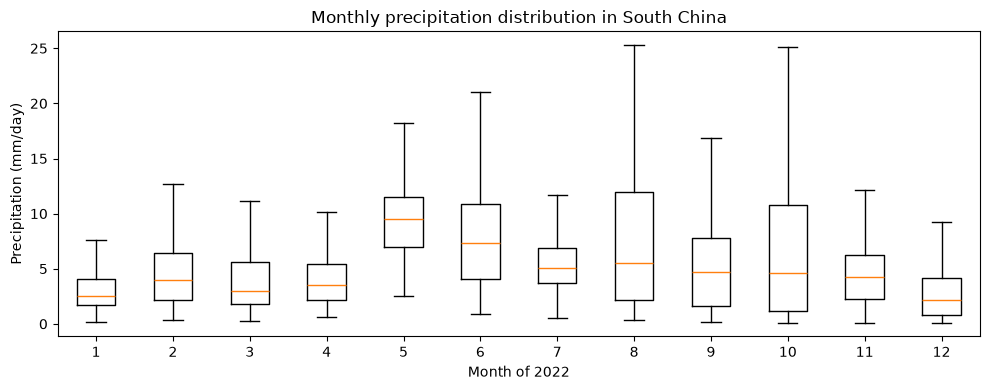

In [5]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
from netCDF4 import Dataset

# 两个 ZIP 与 Notebook 放在同一目录
zip_2022 = next((
    path for path in [
        Path("GPCPMON_2022_01-12_V3.3(1).zip"),
        Path("GPCPMON_2022_01-12_V3.3.zip")
    ]
    if path.exists()
), None)

zip_extra = Path("GPCPMON_2021_2023_supplement_V3.3.zip")

if zip_2022 is None or not zip_extra.exists():
    raise FileNotFoundError("请将 2022 ZIP 和 2021/2023 补充 ZIP 放在运行目录")

data_dir = Path("GPCPMON_2021_2023")
data_dir.mkdir(exist_ok=True)

for zip_path in [zip_2022, zip_extra]:
    with ZipFile(zip_path) as archive:
        archive.extractall(data_dir)

monthly_data = []

for year in range(2021, 2024):
    for month in range(1, 13):
        file = data_dir / f"GPCPMON_L3_{year}{month:02d}_V3.3.nc4"

        with Dataset(file) as ds:
            if year == 2021 and month == 1:
                lat = np.asarray(ds["lat"][:])
                lon = np.asarray(ds["lon"][:])

            monthly_data.append(
                np.ma.filled(
                    ds["sat_gauge_precip"][0, :, :], np.nan
                ).astype(float)
            )

# 36 个月数据；2022 年对应第 13–24 个月
precip = np.stack(monthly_data)
precip_2022 = precip[12:24]
months = np.arange(1, 13)

dates = np.array([
    f"{year}-{month:02d}"
    for year in range(2021, 2024)
    for month in range(1, 13)
])

# 华南区域：15°N–30°N、105°E–125°E
lat_mask = (lat >= 15) & (lat <= 30)
lon_mask = (lon >= 105) & (lon <= 125)
region = precip[:, lat_mask, :][:, :, lon_mask]

weights = np.cos(np.deg2rad(lat[lat_mask]))[None, :, None]
valid = np.isfinite(region)

regional_mean = (
    np.nansum(region * weights, axis=(1, 2))
    / np.sum(np.where(valid, weights, 0), axis=(1, 2))
)


# 3.1 用 2021–2023 年的逐月气候态去除季节循环
monthly_climatology = regional_mean.reshape(3, 12).mean(axis=0)
deseasonalized = regional_mean - np.tile(monthly_climatology, 3)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    np.arange(36), deseasonalized,
    "o-", markersize=3, color="tab:blue"
)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    xticks=np.arange(0, 36, 3),
    xticklabels=dates[::3],
    xlabel="Year-month",
    ylabel="Precipitation anomaly (mm/day)",
    title="South China: monthly climatology removed (2021–2023)"
)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3.2 图一：2022 年全球平均降水地图
annual_mean = np.nanmean(precip_2022, axis=0)

fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.pcolormesh(
    lon, lat, annual_mean,
    shading="auto", cmap="Blues", vmin=0
)
fig.colorbar(image, ax=ax, label="Precipitation (mm/day)")
ax.set(
    xlabel="Longitude (°E)",
    ylabel="Latitude (°N)",
    title="Global annual mean precipitation, 2022"
)
plt.tight_layout()
plt.show()


# 3.2 图二：2022 年月份 × 纬度热力图
latitude_month = np.nanmean(precip_2022, axis=2)

fig, ax = plt.subplots(figsize=(9, 4.5))
image = ax.pcolormesh(
    months, lat, latitude_month.T,
    shading="auto", cmap="YlGnBu"
)
fig.colorbar(image, ax=ax, label="Precipitation (mm/day)")
ax.set(
    xticks=months,
    xlabel="Month of 2022",
    ylabel="Latitude (°N)",
    title="Monthly zonal-mean precipitation"
)
plt.tight_layout()
plt.show()


# 3.2 图三：2022 年平均降水的纬向剖面
zonal_mean = np.nanmean(annual_mean, axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lat, zonal_mean, color="tab:green")
ax.set(
    xlabel="Latitude (°N)",
    ylabel="Precipitation (mm/day)",
    title="Zonal-mean precipitation by latitude"
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3.2 图四：2022 年全球格点降水直方图
values = annual_mean[np.isfinite(annual_mean)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(values, bins=60, color="tab:purple", alpha=0.8)
ax.set(
    xlabel="Annual mean precipitation (mm/day)",
    ylabel="Number of grid cells",
    title="Distribution of annual mean precipitation"
)
plt.tight_layout()
plt.show()


# 3.2 图五：2022 年华南逐月降水箱线图
samples = [
    region[12 + i][np.isfinite(region[12 + i])].ravel()
    for i in range(12)
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(samples, showfliers=False)
ax.set(
    xlabel="Month of 2022",
    ylabel="Precipitation (mm/day)",
    title="Monthly precipitation distribution in South China"
)
plt.tight_layout()
plt.show()